<a href="https://colab.research.google.com/github/Juanse99-lab/Domine-la-Inteligencia-Artificial/blob/main/3%20-%20Conceptos%20clave%20sobre%20inteligencia%20artificial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conceptos claves sobre inteligencia artificial

## Procesamiento de datos

### Limpieza de datos

In [ ]:
import pandas as pd
import os
import kagglehub
import numpy as np

# Download latest version
path = kagglehub.dataset_download("laotse/credit-risk-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'credit-risk-dataset' dataset.
Path to dataset files: /kaggle/input/credit-risk-dataset


In [ ]:
csv_path = os.path.join(path, "credit_risk_dataset.csv")
df = pd.read_csv(csv_path)
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df.isnull().any()

,0
person_age,False
person_income,False
person_home_ownership,False
person_emp_length,True
loan_intent,False
loan_grade,False
loan_amnt,False
loan_int_rate,True
loan_status,False
loan_percent_income,False


In [ ]:
nan_cols = df.columns[df.isnull().any()]
nan_cols

Index(['person_emp_length', 'loan_int_rate'], dtype='object')

In [ ]:
filas_nan = df[df.isna().any(axis=1)]
filas_nan

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
39,23,71500,RENT,3.0,DEBTCONSOLIDATION,D,30000,NaN,1,0.42,N,4
50,24,78000,RENT,4.0,DEBTCONSOLIDATION,D,30000,NaN,1,0.38,Y,4
57,23,277000,OWN,3.0,PERSONAL,A,35000,NaN,0,0.13,N,4
59,24,12000,OWN,2.0,VENTURE,E,1750,NaN,0,0.15,Y,3
62,26,263000,MORTGAGE,0.0,EDUCATION,B,10000,NaN,1,0.04,N,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32547,53,4888,OWN,0.0,VENTURE,C,1400,NaN,1,0.29,Y,28
32552,65,45900,RENT,2.0,EDUCATION,C,10000,NaN,0,0.22,Y,19
32553,54,20000,RENT,2.0,MEDICAL,C,5000,NaN,0,0.25,N,28
32569,51,60000,MORTGAGE,1.0,PERSONAL,A,7500,NaN,0,0.13,N,23


In [ ]:
df.dropna(how='any', inplace=True)
df.shape

(28638, 12)

### Imputación de valores faltantes

In [ ]:
df['person_emp_lenght'] = df['person_emp_length'].replace(np.nan, np.mean(df['person_emp_length']))

In [ ]:
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy='mean')
df['loan_int_rate']=imp.fit_transform(df[['loan_int_rate']])

### Codificación de variables categóricas

In [ ]:
print(df['person_home_ownership'].unique())
print(df['loan_intent'].unique())
print(df['loan_grade'].unique())
print(df['cb_person_default_on_file'].unique())

['RENT' 'OWN' 'MORTGAGE' 'OTHER']
['PERSONAL' 'EDUCATION' 'MEDICAL' 'VENTURE' 'HOMEIMPROVEMENT'
 'DEBTCONSOLIDATION']
['D' 'B' 'C' 'A' 'E' 'F' 'G']
['Y' 'N']


In [ ]:
# Mapeando valores con map()
df['cb_person_default_on_file'] = df['cb_person_default_on_file'].map(
{'Y':1,'N':0})
df['cb_person_default_on_file']

,cb_person_default_on_file
0,1
1,0
2,0
3,0
4,1
...,...
32576,0
32577,0
32578,0
32579,0


In [ ]:
# Convirtiendo la columna a categórica
df['loan_intent'] = df['loan_intent'].astype('category')
df['loan_intent'] = df['loan_intent'].cat.codes
df['loan_intent']

,loan_intent
0,4
1,1
2,3
3,3
4,3
...,...
32576,4
32577,4
32578,2
32579,4


In [ ]:
# Codificador OrdinalEncoder
from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder()
df['loan_grade'] = enc.fit_transform(df[['loan_grade']])
df['person_home_ownership'] = enc.fit_transform(df[['person_home_ownership']])

print(df['loan_grade'])
print(df['person_home_ownership'])

0        3.0
1        1.0
2        2.0
3        2.0
4        2.0
        ... 
32576    2.0
32577    0.0
32578    1.0
32579    1.0
32580    1.0
Name: loan_grade, Length: 28638, dtype: float64
0        3.0
1        2.0
2        0.0
3        3.0
4        3.0
        ... 
32576    0.0
32577    0.0
32578    3.0
32579    0.0
32580    3.0
Name: person_home_ownership, Length: 28638, dtype: float64


In [ ]:
# Codificador LabelEncoder
data = {'asistencia_clases':['baja','media','alta','media','alta'],
        'horas_estudio':[3,8,10,4,6],
        'Aprobado':['Clase 1', 'Clase 2','Clase 2', 'Clase 1', 'Clase 2']}

df_prueba = pd.DataFrame(data, columns=['asistencia_clases','horas_estudio', 'Aprobado'])
print(df_prueba)

from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_prueba['Aprobado']= enc.fit_transform(df_prueba['Aprobado'])
print(df_prueba)

  asistencia_clases  horas_estudio Aprobado
0              baja              3  Clase 1
1             media              8  Clase 2
2              alta             10  Clase 2
3             media              4  Clase 1
4              alta              6  Clase 2
  asistencia_clases  horas_estudio  Aprobado
0              baja              3         0
1             media              8         1
2              alta             10         1
3             media              4         0
4              alta              6         1


In [ ]:
# Codificación One-Hot
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown='ignore')
enc_df = pd.DataFrame(enc.fit_transform(df_prueba[['asistencia_clases']]).toarray(), columns= enc.categories_[0])
df_prueba = df_prueba.join(enc_df)
df_prueba

,asistencia_clases,horas_estudio,Aprobado,alta,baja,media
0,baja,3,0,0.0,1.0,0.0
1,media,8,1,0.0,0.0,1.0
2,alta,10,1,1.0,0.0,0.0
3,media,4,0,0.0,0.0,1.0
4,alta,6,1,1.0,0.0,0.0


In [ ]:
# One-Hot con get_dummies
df_prueba = pd.get_dummies(df_prueba, prefix = "asistencia", columns=['asistencia_clases'])
df_prueba

,horas_estudio,Aprobado,alta,baja,media,asistencia_alta,asistencia_baja,asistencia_media
0,3,0,0.0,1.0,0.0,False,True,False
1,8,1,0.0,0.0,1.0,False,False,True
2,10,1,1.0,0.0,0.0,True,False,False
3,4,0,0.0,0.0,1.0,False,False,True
4,6,1,1.0,0.0,0.0,True,False,False


### Escalado de datos

In [ ]:
# Normalización
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
horas_esc = min_max_scaler.fit_transform(df_prueba[['horas_estudio']])
horas_esc

array([[0.        ],
       [0.71428571],
       [1.        ],
       [0.14285714],
       [0.42857143]])

In [ ]:
# Estandarización
from sklearn.preprocessing import StandardScaler
std_scaler = StandardScaler()
horas_est = std_scaler.fit_transform(df_prueba[['horas_estudio']])
horas_est

array([[-1.2493901 ],
       [ 0.70278193],
       [ 1.48365074],
       [-0.85895569],
       [-0.07808688]])

In [ ]:
# inverse_transform
std_scaler.inverse_transform(horas_est)

array([[ 3.],
       [ 8.],
       [10.],
       [ 4.],
       [ 6.]])

### División del conjunto de datos

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns = df.columns[8])
y = df.iloc[:,8]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state = 1000)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((21478, 12), (7160, 12), (21478,), (7160,))

### [Selección de características](https://www.youtube.com/watch?v=l3OmtvcaTmM)

### Reducción de la dimensionalidad

In [ ]:
# PCA
est_esc = StandardScaler()
est_esc.fit(X_train)
X_ent_est = est_esc.transform(X_train)
X_pru_est = est_esc.transform(X_test)
print(X_ent_est[0])
print('----------------------------------------------')

from sklearn.decomposition import PCA
pca = PCA(n_components=5)
X_ent_pca = pca.fit_transform(X_ent_est)
print(X_ent_pca)
print('----------------------------------------------')

pca_df = pd.DataFrame(pca.components_.T, columns=["PC1","PC2","PC3","PC4","PC5"], index=X.columns)
print(pca_df)
print('----------------------------------------------')

print(f'PCA Ratio: {pca.explained_variance_ratio_}')
print(f'PCA CumSum: {np.cumsum(pca.explained_variance_ratio_)}')
print('------------------------------------------------')

X_pru_pca = pca.transform(X_pru_est)
print(X_pru_pca)
print('------------------------------------------------')

print(X_pru_pca.shape)
print(X_ent_pca.shape)
print('------------------------------------------------')

[-0.89784961 -0.41904959  0.92425684  0.29025297 -0.30583996  0.66617171
 -0.57787975  0.67990133 -0.18070767  2.15790894 -0.93742781  0.29025297]
----------------------------------------------
[[ 1.68978098  0.43369043 -0.92855154 -1.48888144 -0.72782993]
 [-0.14853146 -1.69098203 -0.91558893  1.11862363 -0.46740498]
 [-1.00451468  0.09575124 -0.16732552 -1.05937702  0.27302254]
 ...
 [-0.82131957  0.48404765 -1.83630613  0.93705715 -0.81053842]
 [-0.06788503 -2.50054005  0.52331739 -0.17461472 -0.28402131]
 [-0.4422849  -1.71814197  0.19711106 -0.5974743  -0.65811978]]
----------------------------------------------
                                 PC1       PC2       PC3       PC4       PC5
person_age                 -0.222133  0.340687  0.544778  0.146454 -0.059313
person_income              -0.164636  0.181235  0.043693 -0.032839  0.714298
person_home_ownership       0.244236 -0.087041  0.186970  0.073814 -0.453894
person_emp_length          -0.389559  0.353590 -0.350543 -0.152698 

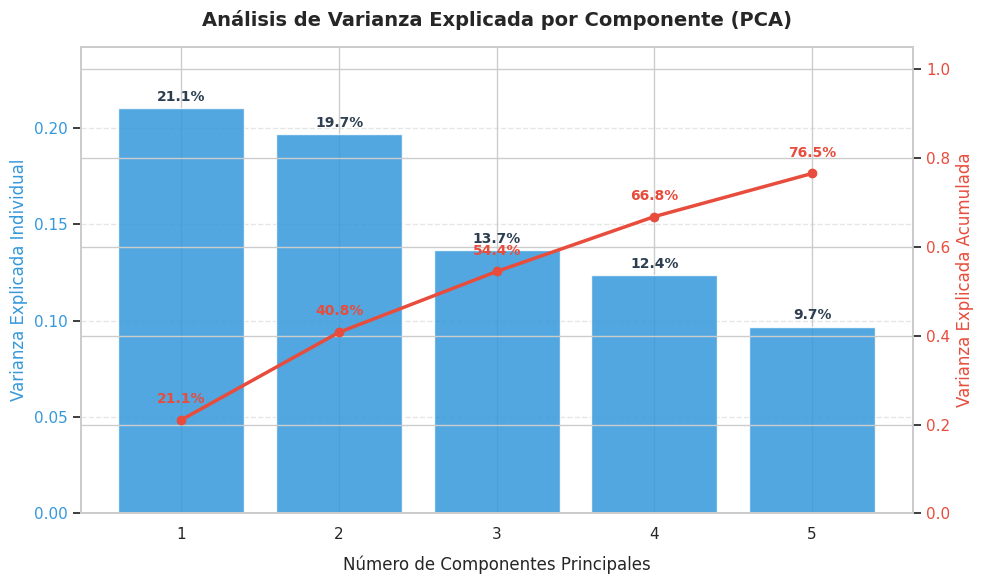

In [ ]:
import matplotlib.pyplot as plt
# Datos de varianza
individual_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(individual_variance)
components = range(1, len(individual_variance) + 1)

# Crear figura y primer eje (barras)
fig, ax1 = plt.subplots(figsize=(10, 6))

color_bars = '#3498db'  # Azul suave
ax1.set_xlabel('Número de Componentes Principales', fontsize=12, labelpad=10)
ax1.set_ylabel('Varianza Explicada Individual', color=color_bars, fontsize=12)
bars = ax1.bar(components, individual_variance, color=color_bars, alpha=0.85, label='Varianza Individual')
ax1.tick_params(axis='y', labelcolor=color_bars)
ax1.set_ylim(0, max(individual_variance) * 1.15)  # Dar espacio para las etiquetas

# Añadir etiquetas de porcentaje sobre cada barra
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f'{height:.1%}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # Desfase vertical de 3 puntos
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2c3e50')

# Crear segundo eje (línea acumulada)
ax2 = ax1.twinx()
color_line = '#e74c3c'  # Rojo suave
ax2.set_ylabel('Varianza Explicada Acumulada', color=color_line, fontsize=12)
line = ax2.plot(components, cumulative_variance, color=color_line, marker='o', linewidth=2.5, label='Varianza Acumulada')
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.set_ylim(0, 1.05)  # Eje porcentual hasta un poco más del 100%

# Añadir etiquetas de porcentaje sobre los puntos de la línea acumulada
for x, y in zip(components, cumulative_variance):
    ax2.annotate(f'{y:.1%}',
                 xy=(x, y),
                 xytext=(0, 10),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color=color_line)

# Configuración de diseño general
plt.title('Análisis de Varianza Explicada por Componente (PCA)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(components)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')

fig.tight_layout()
plt.show()